In [1]:
import torch
import matplotlib.pyplot as plt

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device


'cpu'

In [34]:
from sklearn.datasets import make_moons

# HYPERPARAMETERS
RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)

n_samples = 1000

X, y = make_moons(n_samples=n_samples, noise = 0.07, random_state=RANDOM_SEED)  # didn't know by heart
print(X.dtype)
print(y.dtype)
print(" ")
print(X.shape)
print(y.shape)
print(" ")
print(type(X))
print(type(y))

# transform NumPy array to a PyTorch tensor float

X = torch.from_numpy(X).type(torch.float)                         # didn't know by heart
y = torch.from_numpy(y).type(torch.float)
print(" ")
print(X.dtype)
print(y.dtype)

# split the data into a train / test split using 'train_test_split'

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,            # didn't know by heart
                                                    y,
                                                    test_size=0.2, # split into 80% train 20% test
                                                    random_state=RANDOM_SEED)
print(" ")
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)
print(" ")
print(X[:10])
print(y[:10])



float64
int64
 
(1000, 2)
(1000,)
 
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
 
torch.float32
torch.float32
 
torch.Size([800, 2])
torch.Size([200, 2])
torch.Size([800])
torch.Size([200])
 
tensor([[-0.0334,  0.4214],
        [ 0.9988, -0.4429],
        [ 0.8896, -0.3278],
        [ 0.3420, -0.4177],
        [-0.8385,  0.5324],
        [ 0.5991, -0.2898],
        [ 0.2901, -0.2047],
        [-0.0383,  0.4594],
        [ 1.6138, -0.2940],
        [ 0.6933,  0.8278]])
tensor([1., 1., 1., 1., 0., 1., 1., 1., 1., 0.])


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,            # didn't know by heart
                                                    y,
                                                    test_size=0.2, # split into 80% train 20% test
                                                    random_state=RANDOM_SEED)



(800, 200, 800, 200)

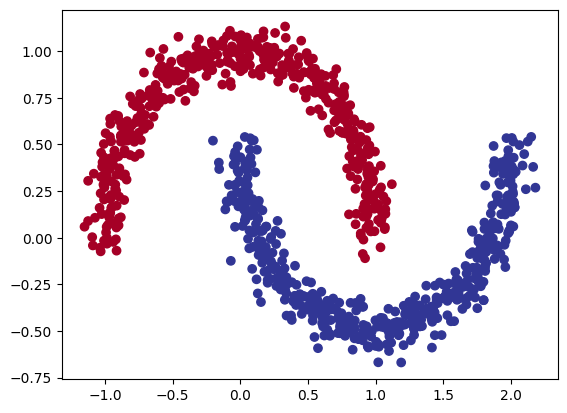

In [5]:
# visualize

import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu)     # X[:, 0] — slicing a 2D array. The comma separates dimensions: before it, which rows; after it, which columns. : means "all". So X[:, 0] reads every row, column 0 → all 1000 first-features, as a 1D array of length 1000. // is the same for column 1
plt.show()

In [6]:
import pandas as pd         # ah ok this part i didn't know what the instruction was actually about

data_df = pd.DataFrame({"X0": X[:, 0],
                        "X1": X[:, 1],
                        "y": y})
data_df.head()

,X0,X1,y
0,-0.033411,0.421391,1.0
1,0.998827,-0.442890,1.0
2,0.889592,-0.327843,1.0
3,0.341958,-0.417690,1.0
4,-0.838531,0.532375,0.0


In [7]:
# build a Model by subclassing nn.Module

import torch
from torch import nn

class MoonModelV0(nn.Module):
    def __init__(self, in_features, out_features, hidden_units):
      super().__init__()

      self.Layer_1 = (nn.Linear(in_features=in_features,
                                 out_features=hidden_units))
      self.Layer_2 = (nn.Linear(in_features=hidden_units,
                                 out_features=hidden_units))
      self.Layer_3 = (nn.Linear(in_features=hidden_units,
                                 out_features=out_features))
      self.relu = nn.ReLU()

    def forward(self, x):
      return self.Layer_3(self.relu(self.Layer_2(self.relu(self.Layer_1(x)))))

Model_0 = MoonModelV0(
                      in_features=2,
                      out_features=1,
                      hidden_units=8
).to(device)
Model_0

MoonModelV0(
  (Layer_1): Linear(in_features=2, out_features=8, bias=True)
  (Layer_2): Linear(in_features=8, out_features=8, bias=True)
  (Layer_3): Linear(in_features=8, out_features=1, bias=True)
  (relu): ReLU()
)

In [8]:
"""
# without hardcoding the values

import torch
from torch import nn

class MoonModelV0bis(nn.Module):
  def __init__(self):
      super().__init__()


      self.layers = nn.Sequential(
          nn.Linear(in_features=2, out_features=8),
          nn.ReLU(),
          nn.Linear(in_features=8, out_features=8),
          nn.ReLU(),
          nn.Linear(in_features=8, out_features=1)
      )

  def forward(self, x):
    return self.layers(x)
"""

'\n# without hardcoding the values \n\nimport torch \nfrom torch import nn\n\nclass MoonModelV0bis(nn.Module):\n  def __init__(self):\n      super().__init__()\n\n\n      self.layers = nn.Sequential(\n          nn.Linear(in_features=2, out_features=8),\n          nn.ReLU(),\n          nn.Linear(in_features=8, out_features=8),\n          nn.ReLU(),\n          nn.Linear(in_features=8, out_features=1)\n      )\n\n  def forward(self, x):\n    return self.layers(x)\n'

In [9]:
Model_0.state_dict()

OrderedDict([('Layer_1.weight',
              tensor([[ 0.5406,  0.5869],
                      [-0.1657,  0.6496],
                      [-0.1549,  0.1427],
                      [-0.3443,  0.4153],
                      [ 0.6233, -0.5188],
                      [ 0.6146,  0.1323],
                      [ 0.5224,  0.0958],
                      [ 0.3410, -0.0998]])),
             ('Layer_1.bias',
              tensor([ 0.5451,  0.1045, -0.3301,  0.1802, -0.3258, -0.0829, -0.2872,  0.4691])),
             ('Layer_2.weight',
              tensor([[-0.2791, -0.1630, -0.0998, -0.2126,  0.0334, -0.3492,  0.3193, -0.3003],
                      [ 0.2730,  0.0588, -0.1148,  0.2185,  0.0551,  0.2857,  0.0387, -0.1115],
                      [ 0.0950, -0.0959,  0.1488,  0.3157,  0.2044, -0.1546,  0.2041,  0.0633],
                      [ 0.1795, -0.2155, -0.3500, -0.1366, -0.2712,  0.2901,  0.1018,  0.1464],
                      [ 0.1118, -0.0062,  0.2767, -0.2512,  0.0223, -0.2413,  0.1090, 

In [10]:
type(Model_0)

__main__.MoonModelV0

In [11]:
loss_fn = nn.BCEWithLogitsLoss()      # else I could have used N1Loss
optimizer = torch.optim.SGD(params=Model_0.parameters(), lr=0.1)


In [35]:
# from logits to probs to preds
logits = Model_0(X_train.to(device)[:10]).squeeze()
print(logits)
print(" ")
probabilities = torch.sigmoid(logits)
print(probabilities)
print(" ")
predictions = torch.round(probabilities)
print(predictions)


tensor([ 5.0186, -4.9520, -3.9326, -3.2242,  4.8835, -3.6005,  4.4523,  4.1326,
        -5.9976, -3.4899], grad_fn=<SqueezeBackward0>)
 
tensor([0.9934, 0.0070, 0.0192, 0.0383, 0.9925, 0.0266, 0.9885, 0.9842, 0.0025,
        0.0296], grad_fn=<SigmoidBackward0>)
 
tensor([1., 0., 0., 0., 1., 0., 1., 1., 0., 0.], grad_fn=<RoundBackward0>)


In [13]:
# let's add accuracy

!pip -q install torchmetrics # colab doesn't come with torchmetrics
from torchmetrics import Accuracy

acc_fn = Accuracy(task="multiclass", num_classes=2).to(device) # send accuracy function to device
acc_fn

MulticlassAccuracy()

In [14]:
# HYPERPARAMETERS

EPOCHS = 1000
MANUAL_SEED = 42
torch.manual_seed(MANUAL_SEED)

# Loop

for epoch in range(EPOCHS):
  Model_0.train()

  # forward pass
  y_logits = Model_0(X_train.to(device)).squeeze()
  y_pred = torch.round(torch.sigmoid(y_logits))

  # calculate loss
  loss = loss_fn(y_logits, y_train.to(device))

  # accuracy
  train_acc = acc_fn(y_pred, y_train.to(device))

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  # Testing

  Model_0.eval()
  with torch.inference_mode():
    test_logits = Model_0(X_test.to(device)).squeeze()
    test_pred = torch.round(torch.sigmoid(test_logits))
    test_loss = loss_fn(test_logits, y_test.to(device))
    test_acc = acc_fn(test_pred, y_test.to(device))

  if epoch % 10 == 0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f} | Train Acc: {train_acc:.2f} | Test Loss: {test_loss:.5f} | Test Acc: {test_acc:.2f}")



Epoch: 0 | Loss: 0.71201 | Train Acc: 0.50 | Test Loss: 0.70540 | Test Acc: 0.50
Epoch: 10 | Loss: 0.69035 | Train Acc: 0.59 | Test Loss: 0.68809 | Test Acc: 0.63
Epoch: 20 | Loss: 0.67924 | Train Acc: 0.80 | Test Loss: 0.67869 | Test Acc: 0.83
Epoch: 30 | Loss: 0.66641 | Train Acc: 0.84 | Test Loss: 0.66690 | Test Acc: 0.81
Epoch: 40 | Loss: 0.64711 | Train Acc: 0.82 | Test Loss: 0.64878 | Test Acc: 0.80
Epoch: 50 | Loss: 0.61797 | Train Acc: 0.82 | Test Loss: 0.62134 | Test Acc: 0.79
Epoch: 60 | Loss: 0.57630 | Train Acc: 0.82 | Test Loss: 0.58185 | Test Acc: 0.80
Epoch: 70 | Loss: 0.52202 | Train Acc: 0.82 | Test Loss: 0.53025 | Test Acc: 0.81
Epoch: 80 | Loss: 0.46207 | Train Acc: 0.83 | Test Loss: 0.47267 | Test Acc: 0.82
Epoch: 90 | Loss: 0.40695 | Train Acc: 0.83 | Test Loss: 0.41903 | Test Acc: 0.82
Epoch: 100 | Loss: 0.36405 | Train Acc: 0.84 | Test Loss: 0.37636 | Test Acc: 0.83
Epoch: 110 | Loss: 0.33301 | Train Acc: 0.86 | Test Loss: 0.34451 | Test Acc: 0.84
Epoch: 120 | Lo

In [15]:
# Plot the model predictions

import numpy as np

# I am not expected to knwo how to do this from scratch
# TK - this could go in the helper_functions.py and be explained there
def plot_decision_boundary(model, X, y):

    # Put everything to CPU (works better with NumPy + Matplotlib)
    model.to("cpu")
    X, y = X.to("cpu"), y.to("cpu")

    # Source - https://madewithml.com/courses/foundations/neural-networks/
    # (with modifications)
    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 101),
                         np.linspace(y_min, y_max, 101))

    # Make features
    X_to_pred_on = torch.from_numpy(np.column_stack((xx.ravel(), yy.ravel()))).float()

    # Make predictions
    model.eval()
    with torch.inference_mode():
        y_logits = model(X_to_pred_on)

    # Test for multi-class or binary and adjust logits to prediction labels
    if len(torch.unique(y)) > 2:
        y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1) # mutli-class
    else:
        y_pred = torch.round(torch.sigmoid(y_logits)) # binary

    # Reshape preds and plot
    y_pred = y_pred.reshape(xx.shape).detach().numpy()
    plt.contourf(xx, yy, y_pred, cmap=plt.cm.RdYlBu, alpha=0.7)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.RdYlBu)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())

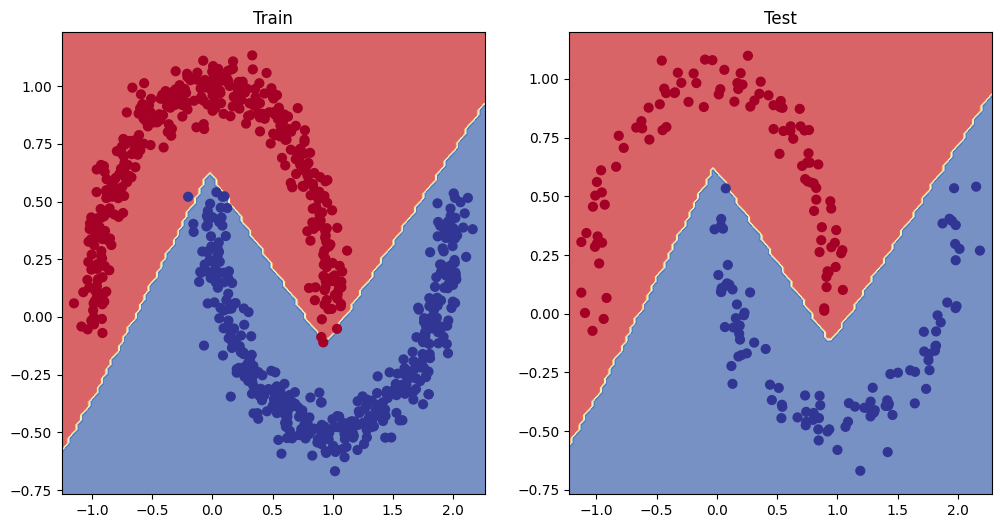

In [16]:

# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(Model_0, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(Model_0, X_test, y_test)


In [22]:
# replicate tanh function

A = torch.arange(-100, 100, 1)
A

tensor([-100,  -99,  -98,  -97,  -96,  -95,  -94,  -93,  -92,  -91,  -90,  -89,
         -88,  -87,  -86,  -85,  -84,  -83,  -82,  -81,  -80,  -79,  -78,  -77,
         -76,  -75,  -74,  -73,  -72,  -71,  -70,  -69,  -68,  -67,  -66,  -65,
         -64,  -63,  -62,  -61,  -60,  -59,  -58,  -57,  -56,  -55,  -54,  -53,
         -52,  -51,  -50,  -49,  -48,  -47,  -46,  -45,  -44,  -43,  -42,  -41,
         -40,  -39,  -38,  -37,  -36,  -35,  -34,  -33,  -32,  -31,  -30,  -29,
         -28,  -27,  -26,  -25,  -24,  -23,  -22,  -21,  -20,  -19,  -18,  -17,
         -16,  -15,  -14,  -13,  -12,  -11,  -10,   -9,   -8,   -7,   -6,   -5,
          -4,   -3,   -2,   -1,    0,    1,    2,    3,    4,    5,    6,    7,
           8,    9,   10,   11,   12,   13,   14,   15,   16,   17,   18,   19,
          20,   21,   22,   23,   24,   25,   26,   27,   28,   29,   30,   31,
          32,   33,   34,   35,   36,   37,   38,   39,   40,   41,   42,   43,
          44,   45,   46,   47,   48,   

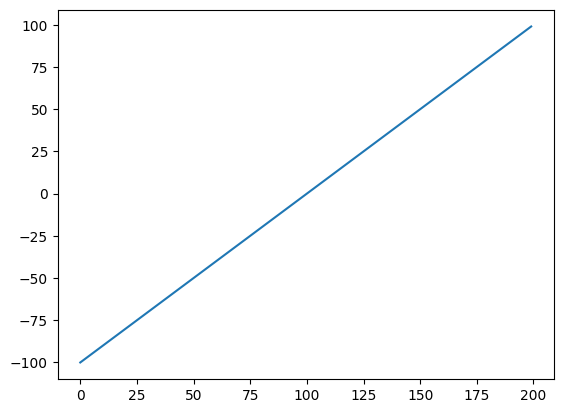

In [24]:
plt.plot(A)

In [25]:
AT = torch.tanh(A)
AT

tensor([-1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -0.9999,
        -0.9993, -0.9951, -0.9640, -0.76

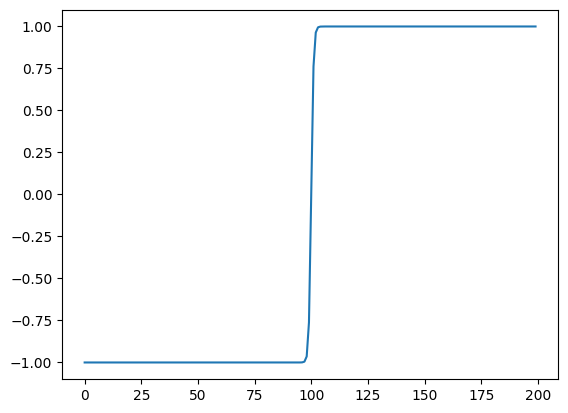

In [26]:
plt.plot(AT)

In [28]:
def custom_tanh(x):
  return (torch.exp(x) - torch.exp(-x)) / (torch.exp(x) + torch.exp(-x))    # https://ml-cheatsheet.readthedocs.io/en/latest/activation_functions.html#tanh$0

In [29]:
ACT = custom_tanh(A)
ACT


tensor([    nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,
            nan,     nan,     nan,     nan, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -0.9999,
        -0.9993, -0.9951, -0.9640, -0.76

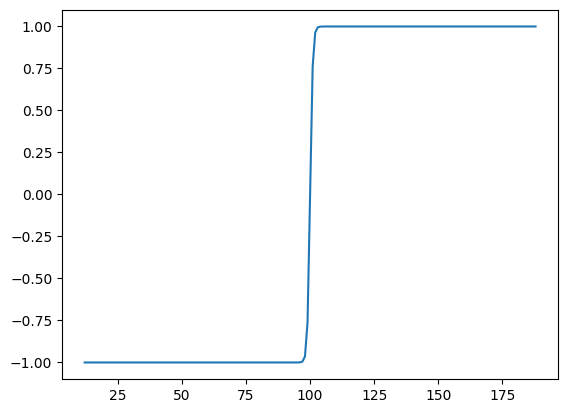

In [30]:
plt.plot(ACT)